## Experiment 9 — Decision Trees & Random Forest Ensemble
**Dataset:** Housing Dataset (Real-Estate Pricing)  
**Objective:** Compare interpretable tree models against an ensemble Random Forest, analyze overfitting via depth restriction, and quantify feature contributions.  
**Techniques:** Decision Tree (Gini, full & restricted depth), Random Forest (OOB validation, n_estimators tuning), permutation importance, feature importance comparison, cross-validation.

### 1. Setup & Imports
Import scikit-learn tree and ensemble estimators, model selection utilities (cross_val_score, train_test_split), and permutation importance. Set a random seed for reproducibility.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

### 2. Load & Prepare Dataset
Load the preprocessed dataset, define the target variable, and select predictor features. Ensure there are no remaining NaN values that would cause tree splitting to fail.

In [2]:
df = pd.read_csv("Housing.csv")
print("Dataset shape:", df.shape)

Dataset shape: (545, 13)


### 3. Train / Test Split
Partition data 80/20. Consistent splitting across experiments enables fair comparison of model performance.

In [3]:
target = "airconditioning"
positive_class = "yes"
predictors = ["area", "bedrooms", "bathrooms", "stories", "parking", "price"]
model_df = df[[target] + predictors].dropna()

X = model_df[predictors]
y = (model_df[target] == positive_class).astype(int)
print("Target counts:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train set size:", len(X_train), "| Test set size:", len(X_test))

Target counts:
 airconditioning
0    373
1    172
Name: count, dtype: int64
Train set size: 436 | Test set size: 109


### 4. Decision Tree — Full Depth (Baseline)
Train an unconstrained Decision Tree with Gini impurity. A fully grown tree typically overfits the training data (low bias, high variance), establishing a performance ceiling that ensemble methods aim to surpass on unseen data.

In [4]:
results, preds, probs = [], {}, {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall": recall_score(y_test, preds[name], zero_division=0),
        "F1": f1_score(y_test, preds[name], zero_division=0),
        "AUC": roc_auc_score(y_test, probs[name])
    })
    print(name, results[-1])
    return model

### 5. Decision Tree — Restricted Depth
Train a Decision Tree with a limited `max_depth` to control overfitting. Depth restriction acts as regularisation: it increases bias slightly but reduces variance, often yielding better generalisation. Compare test accuracy with the full-depth tree.

Decision Tree (full) {'Model': 'Decision Tree (full)', 'Train Accuracy': 0.9977064220183486, 'Accuracy': 0.6972477064220184, 'Precision': 0.5185185185185185, 'Recall': 0.4117647058823529, 'F1': 0.45901639344262296, 'AUC': 0.6192156862745097}
Full Tree Depth: 14 | Leaves: 113
Decision Tree (restricted) {'Model': 'Decision Tree (restricted)', 'Train Accuracy': 0.7706422018348624, 'Accuracy': 0.7339449541284404, 'Precision': 0.631578947368421, 'Recall': 0.35294117647058826, 'F1': 0.4528301886792453, 'AUC': 0.7501960784313726}
Restricted Tree Depth: 4 | Leaves: 15


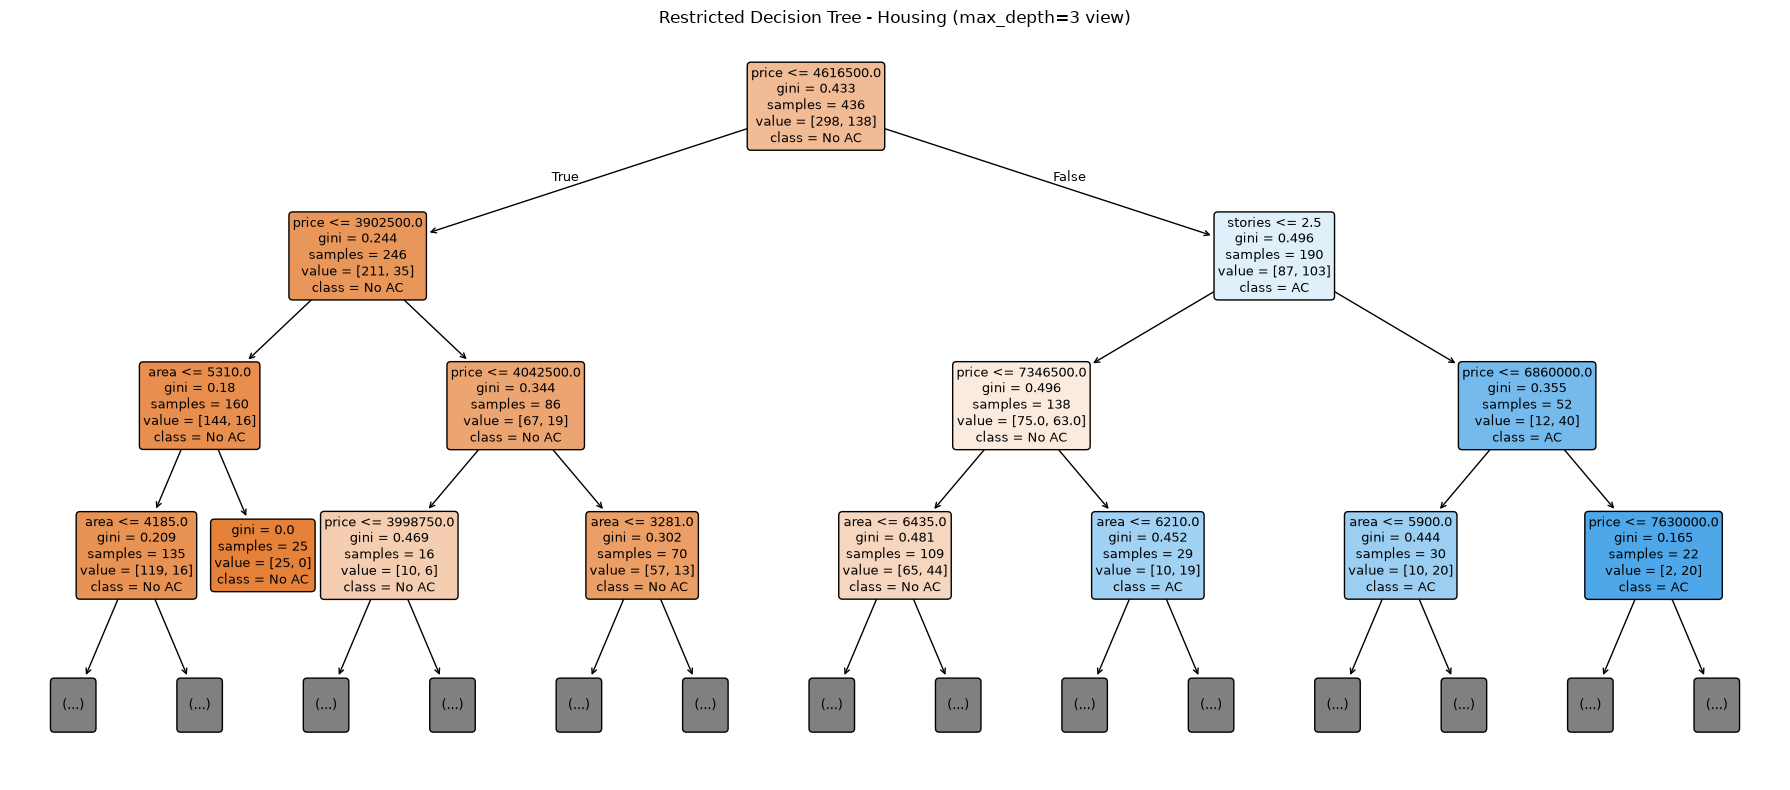

In [5]:
dt = evaluate("Decision Tree (full)", DecisionTreeClassifier(criterion="gini", random_state=42))
print("Full Tree Depth:", dt.get_depth(), "| Leaves:", dt.get_n_leaves())

dt_small = evaluate("Decision Tree (restricted)",
                    DecisionTreeClassifier(criterion="gini", max_depth=4,
                                           min_samples_split=10, min_samples_leaf=5, random_state=42))
print("Restricted Tree Depth:", dt_small.get_depth(), "| Leaves:", dt_small.get_n_leaves())

plt.figure(figsize=(18, 8))
plot_tree(dt_small, max_depth=3, feature_names=predictors,
          class_names=["No AC", "AC"],
          filled=True, rounded=True, fontsize=9)
plt.title("Restricted Decision Tree - Housing (max_depth=3 view)")
plt.tight_layout()
plt.show()

### 6. Random Forest — n_estimators Tuning
Train Random Forests with increasing numbers of trees (`n_estimators`). Plot OOB (Out-Of-Bag) error vs. number of trees to identify the point of diminishing returns. OOB error provides an unbiased estimate of generalisation error without a separate validation set.

In [6]:
rf = evaluate("Random Forest",
              RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1))
print("Random Forest OOB Score:", round(rf.oob_score_, 4))

Random Forest {'Model': 'Random Forest', 'Train Accuracy': 0.9977064220183486, 'Accuracy': 0.7614678899082569, 'Precision': 0.6666666666666666, 'Recall': 0.47058823529411764, 'F1': 0.5517241379310345, 'AUC': 0.7337254901960785}
Random Forest OOB Score: 0.7179


### 7. Random Forest — Final Model & Evaluation
Fit the final Random Forest with the chosen `n_estimators` and evaluate on the held-out test set. Compare accuracy, precision, recall, and F1 against the Decision Tree baselines to quantify the ensemble benefit.

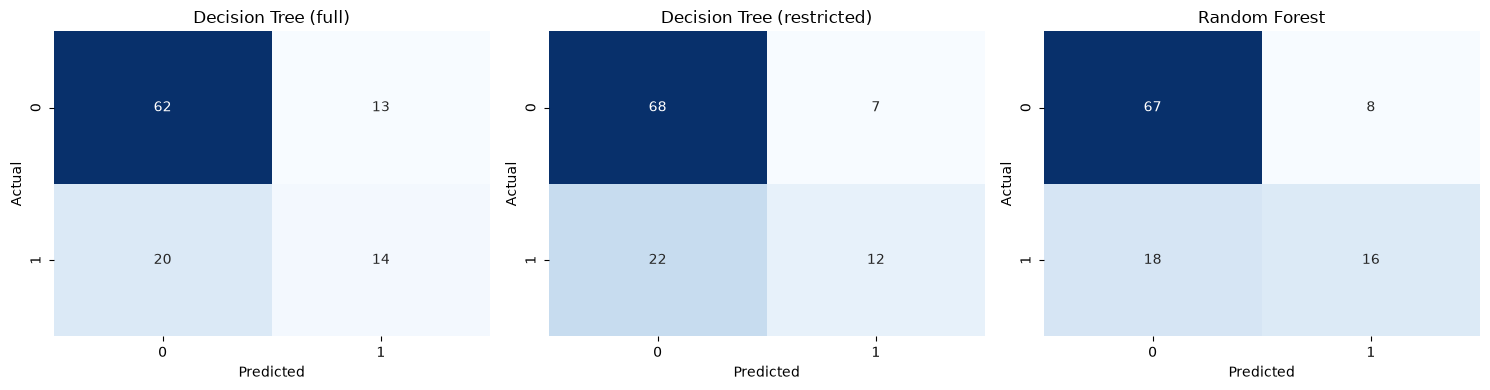

=== Decision Tree (full) ===
              precision    recall  f1-score   support

           0       0.76      0.83      0.79        75
           1       0.52      0.41      0.46        34

    accuracy                           0.70       109
   macro avg       0.64      0.62      0.62       109
weighted avg       0.68      0.70      0.69       109

=== Decision Tree (restricted) ===
              precision    recall  f1-score   support

           0       0.76      0.91      0.82        75
           1       0.63      0.35      0.45        34

    accuracy                           0.73       109
   macro avg       0.69      0.63      0.64       109
weighted avg       0.72      0.73      0.71       109

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.79      0.89      0.84        75
           1       0.67      0.47      0.55        34

    accuracy                           0.76       109
   macro avg       0.73      0.68      0.6

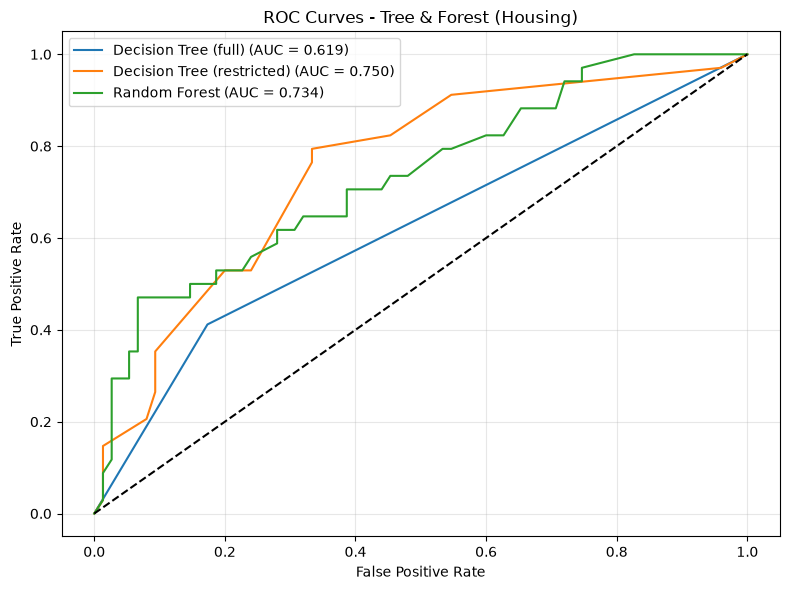

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

for name, pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, zero_division=0))

plt.figure(figsize=(8, 6))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Tree & Forest (Housing)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Feature Importance — Gini Impurity
Extract mean Gini impurity decrease for each feature from the trained Random Forest. Features that consistently reduce impurity across many trees are ranked highest. Visualise as a horizontal bar chart.

Feature Importances:
            Decision Tree  Random Forest  Permutation (mean)  Permutation (std)
price             0.4485         0.4099              0.0963             0.0244
area              0.3829         0.3135              0.0193             0.0171
stories           0.0621         0.1027              0.0128             0.0250
parking           0.0281         0.0683              0.0248             0.0201
bedrooms          0.0463         0.0634             -0.0037             0.0124
bathrooms         0.0321         0.0422              0.0248             0.0159


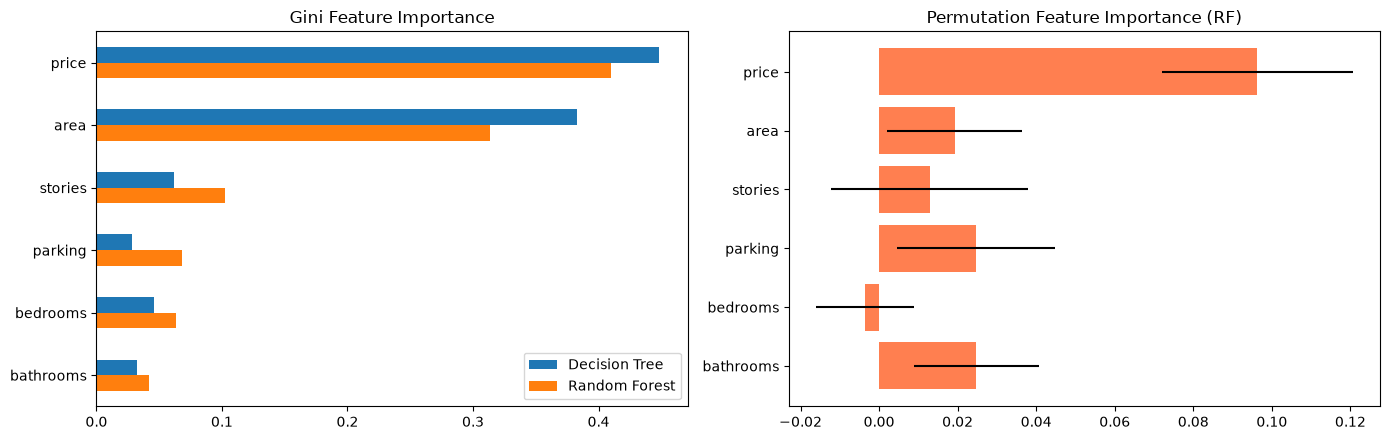

In [8]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, scoring="accuracy", random_state=42)
importance = pd.DataFrame({
    "Decision Tree": dt.feature_importances_,
    "Random Forest": rf.feature_importances_,
    "Permutation (mean)": perm.importances_mean,
    "Permutation (std)": perm.importances_std
}, index=predictors).sort_values("Random Forest", ascending=False)
print("Feature Importances:\n", importance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
importance[["Decision Tree", "Random Forest"]].plot(kind="barh", ax=axes[0])
axes[0].set_title("Gini Feature Importance")
axes[0].invert_yaxis()

axes[1].barh(importance.index, importance["Permutation (mean)"], xerr=importance["Permutation (std)"], color="coral")
axes[1].set_title("Permutation Feature Importance (RF)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

### 9. Permutation Feature Importance
Compute permutation importance by randomly shuffling each feature column on the test set and measuring the resulting drop in accuracy. Unlike Gini importance, permutation importance is model-agnostic and unbiased towards high-cardinality features.

Tree Count Tuning:
    Trees  CV Accuracy   CV F1  CV AUC
0     10       0.7110  0.4910  0.6803
1     25       0.7225  0.5346  0.6990
2     50       0.7270  0.5303  0.7153
3    100       0.7270  0.5380  0.7256
4    200       0.7224  0.5191  0.7239


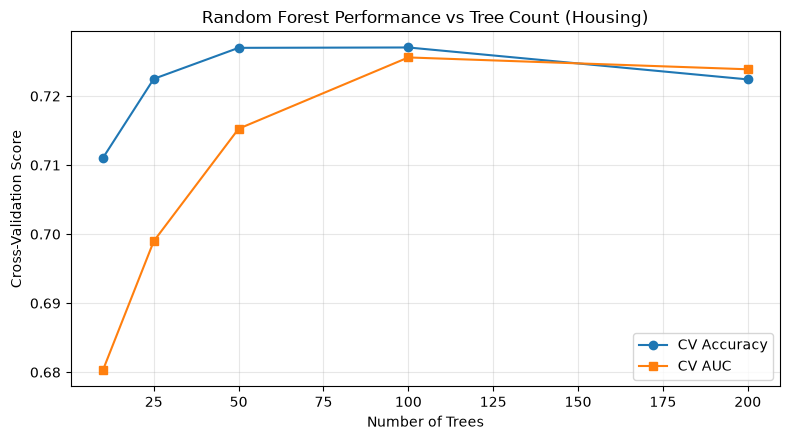

In [9]:
tree_rows = []
for n in [10, 25, 50, 100, 200]:
    cv = cross_validate(RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1),
                        X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"])
    tree_rows.append({
        "Trees": n,
        "CV Accuracy": cv["test_accuracy"].mean(),
        "CV F1": cv["test_f1"].mean(),
        "CV AUC": cv["test_roc_auc"].mean()
    })
tree_results = pd.DataFrame(tree_rows)
print("Tree Count Tuning:\n", tree_results.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(tree_results["Trees"], tree_results["CV Accuracy"], marker="o", label="CV Accuracy")
plt.plot(tree_results["Trees"], tree_results["CV AUC"], marker="s", label="CV AUC")
plt.xlabel("Number of Trees")
plt.ylabel("Cross-Validation Score")
plt.title("Random Forest Performance vs Tree Count (Housing)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10. Cross-Validation
Run stratified k-fold cross-validation on the final Random Forest to confirm that the test-set performance is not a lucky split. Report mean and standard deviation of accuracy across folds.

                            Train Accuracy  Accuracy  Precision  Recall  \
Model                                                                     
Decision Tree (full)                0.9977    0.6972     0.5185  0.4118   
Decision Tree (restricted)          0.7706    0.7339     0.6316  0.3529   
Random Forest                       0.9977    0.7615     0.6667  0.4706   

                                F1     AUC  
Model                                       
Decision Tree (full)        0.4590  0.6192  
Decision Tree (restricted)  0.4528  0.7502  
Random Forest               0.5517  0.7337  


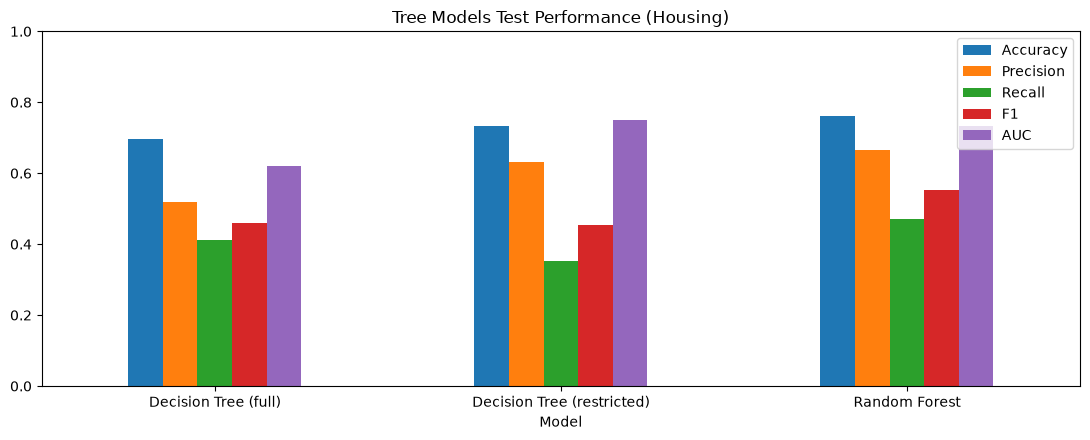

Saved tree model results to CSV files.


In [10]:
comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))

comparison.drop(columns="Train Accuracy").plot(kind="bar", rot=0, figsize=(11, 4.5), ylim=(0, 1))
plt.title("Tree Models Test Performance (Housing)")
plt.tight_layout()
plt.show()

comparison.to_csv("Experiment_9_Model_Results.csv")
importance.to_csv("Experiment_9_Feature_Importance.csv")
tree_results.to_csv("Experiment_9_Tree_Count.csv", index=False)
print("Saved tree model results to CSV files.")